# 06 · Deployment & monitoring: batch scoring, drift, calibration over time

A churn model in a bank typically runs as a **monthly batch job**: score every
active customer, hand the campaign list to CRM, then watch whether the model
still deserves trust. This notebook shows that loop end-to-end with the code
in `src/score.py` and `src/monitoring.py`.

Churn labels arrive ~90 days late, so monitoring cannot wait for them:
1. **Input drift** — has the customer base changed vs training? (PSI per feature)
2. **Score drift** — has the distribution of churn scores moved? (PSI of the score)
3. **Calibration** — once labels arrive: predicted vs observed churn per band.

> The drift scenario in section 3 is **simulated**; the dataset is a single snapshot.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config, path, set_seed
from src.data import CATEGORICAL_COLS, NUMERIC_COLS, prepare_for_scoring
from src.monitoring import PSI_THRESHOLDS, calibration_by_band, drift_report, psi, status
from src.plots import ACCENT, GOOD, MUTED, NEUTRAL, RISK, save, save_table, setup_style
from src.score import load_model, load_reference, score_frame

cfg = load_config()
SEED = set_seed()
setup_style()
pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 60)

model, calibrator = load_model()
reference = load_reference()                       # training features (saved by notebook 02)
holdout = pd.read_csv(path("processed") / "test_predictions.csv")
print(f"reference (train): {len(reference):,} rows | hold-out batch: {len(holdout):,} rows")

reference (train): 8,101 rows | hold-out batch: 2,026 rows


## 1. Batch scoring — what CRM receives
The same function is behind the CLI:
`python -m src.score --input <customers.csv> --output <scored.csv>`

In [2]:
batch = prepare_for_scoring(holdout.drop(columns=["proba", "proba_raw"]))
scored = score_frame(batch, model, calibrator)
print(f"Contact {scored.contact.sum()} of {len(scored)} customers "
      f"({scored.contact.mean():.1%}); expected profit ${scored.loc[scored.contact == 1, 'expected_profit'].sum():,.0f}")
scored.head(8)

Contact 293 of 2026 customers (14.5%); expected profit $13,016


,clientnum,churn_probability,clv,expected_profit,contact,action_family,offer,secondary_family,secondary_offer,top3_drivers
0,759584958,0.9889,1030.08,219.67,1,Reactivation,Category cashback on the customer's top spend category,Credit,Personalised rate or limit offer,"avg_trans_amt, total_trans_amt, total_trans_ct"
1,715321008,0.9990,991.08,212.53,1,Reactivation,Category cashback on the customer's top spend category,Credit,Credit-limit review / debt-restructuring offer,"avg_trans_amt, total_trans_amt, total_trans_ct"
2,717060858,0.9758,998.79,208.65,1,Reactivation,Category cashback on the customer's top spend category,Credit,Credit-limit review / debt-restructuring offer,"avg_trans_amt, total_trans_amt, total_amt_chng_q4_q1"
3,716893683,0.9991,935.37,198.63,1,Reactivation,Category cashback on the customer's top spend category,Credit,Credit-limit review / debt-restructuring offer,"avg_trans_amt, total_trans_ct, total_amt_chng_q4_q1"
4,714615258,0.9760,920.10,189.51,1,Reactivation,Category cashback on the customer's top spend category,Cross-sell,Second product: savings account / debit card / insurance...,"avg_trans_amt, total_trans_ct, total_trans_amt"
5,720597108,0.9764,891.15,182.52,1,Reactivation,Category cashback on the customer's top spend category,none,,"avg_trans_amt, total_trans_ct, total_trans_amt"
6,770038983,0.8556,1015.74,182.26,1,Reactivation,Category cashback on the customer's top spend category,Credit,Credit-limit review / debt-restructuring offer,"avg_trans_amt, total_trans_ct, total_trans_amt"
7,716136333,0.9975,836.85,173.68,1,Reactivation,Spend challenge: cashback for N transactions in 60 days,Credit,Credit-limit review / debt-restructuring offer,"total_trans_ct, total_trans_amt, total_revolving_bal"


## 2. Drift check: hold-out vs training (should be stable)
Train and hold-out come from the same random split, so every PSI should be
far below 0.10. This is the "healthy month" baseline.

In [3]:
healthy = drift_report(reference, batch, NUMERIC_COLS, CATEGORICAL_COLS)
save_table(healthy, "monitoring_psi_healthy")
print("Statuses:", healthy.status.value_counts().to_dict())
healthy.head(6).round(4)

Statuses: {'stable': 19}


,feature,psi,status
0,total_trans_ct,0.0117,stable
1,total_relationship_count,0.0091,stable
2,education_level,0.0065,stable
3,total_trans_amt,0.0052,stable
4,months_on_book,0.0049,stable
5,customer_age,0.0042,stable


## 3. Simulated bad month: a competitor launches a cashback card
**Scenario (assumed):** 35% of customers move part of their spending to a
competitor; their transaction count and amount fall by 40%, and the
quarter-on-quarter change ratios fall accordingly. Nothing else changes.

In [4]:
rng = np.random.default_rng(SEED)
drifted = batch.copy()
hit = rng.random(len(drifted)) < 0.35
for col in ["total_trans_ct", "total_trans_amt"]:
    drifted.loc[hit, col] = (drifted.loc[hit, col] * 0.6).round().astype(int)
for col in ["total_ct_chng_q4_q1", "total_amt_chng_q4_q1"]:
    drifted.loc[hit, col] = drifted.loc[hit, col] * 0.6
drifted = prepare_for_scoring(drifted)     # recompute engineered features consistently

bad = drift_report(reference, drifted, NUMERIC_COLS, CATEGORICAL_COLS)
save_table(bad, "monitoring_psi_drifted")
bad.head(8).round(3)

,feature,psi,status
0,total_amt_chng_q4_q1,0.403,ALERT
1,total_ct_chng_q4_q1,0.306,ALERT
2,total_trans_ct,0.147,investigate
3,total_trans_amt,0.139,investigate
4,total_relationship_count,0.009,stable
5,education_level,0.006,stable
6,months_on_book,0.005,stable
7,customer_age,0.004,stable


In [5]:
scored_bad = score_frame(drifted, model, calibrator)
# Score baseline = calibrated out-of-fold scores on the training set (not seen in fitting)
ref_scores = pd.read_csv(path("processed") / "train_oof_predictions.csv")["proba"]
score_psi_healthy = psi(ref_scores, scored.churn_probability)
score_psi_bad = psi(ref_scores, scored_bad.churn_probability)

summary = pd.DataFrame({
    "month": ["healthy (hold-out)", "simulated drift"],
    "features_flagged": [(healthy.status != "stable").sum(), (bad.status != "stable").sum()],
    "max_feature_psi": [healthy.psi.max(), bad.psi.max()],
    "score_psi": [score_psi_healthy, score_psi_bad],
    "share_to_contact": [scored.contact.mean(), scored_bad.contact.mean()],
    "mean_churn_score": [scored.churn_probability.mean(), scored_bad.churn_probability.mean()],
})
summary["score_status"] = summary.score_psi.map(status)
save_table(summary, "monitoring_summary")
summary.round(3)

,month,features_flagged,max_feature_psi,score_psi,share_to_contact,mean_churn_score,score_status
0,healthy (hold-out),0,0.012,0.023,0.145,0.158,stable
1,simulated drift,4,0.403,0.330,0.343,0.336,ALERT


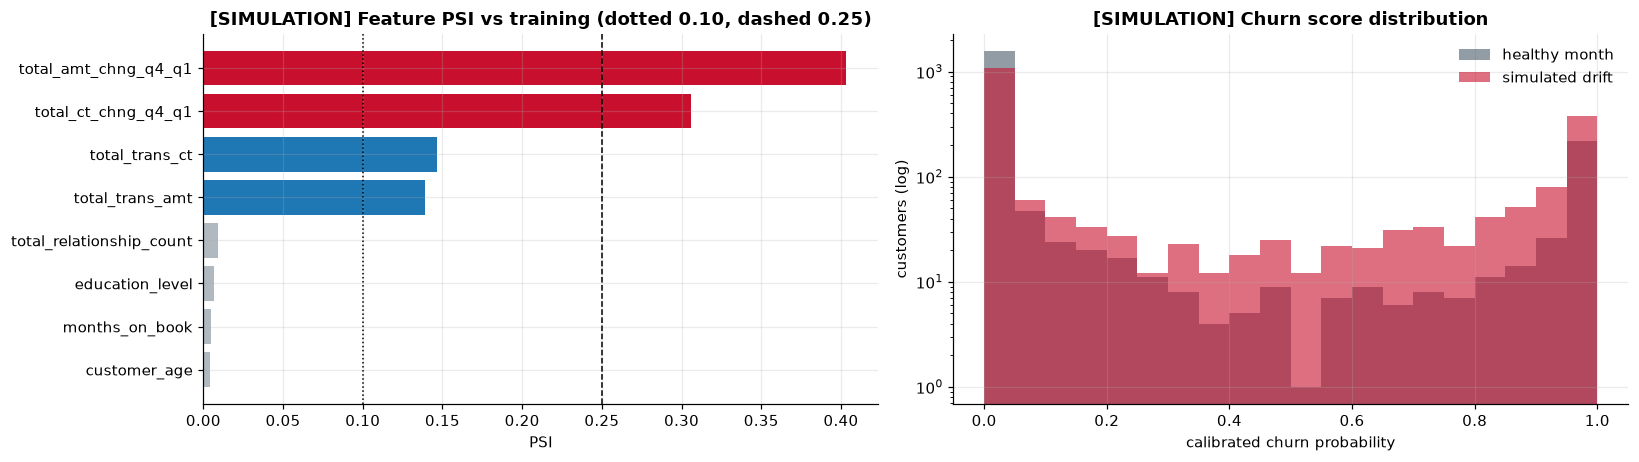

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
top = bad.head(8)[::-1]
axes[0].barh(top.feature, top.psi, color=[RISK if s == "ALERT" else (ACCENT if s == "investigate" else MUTED) for s in top.status])
for t, ls in zip(PSI_THRESHOLDS, [":", "--"]):
    axes[0].axvline(t, color="black", ls=ls, lw=1)
axes[0].set(title="[SIMULATION] Feature PSI vs training (dotted 0.10, dashed 0.25)", xlabel="PSI")
bins = np.linspace(0, 1, 21)
axes[1].hist(scored.churn_probability, bins=bins, alpha=0.6, color=NEUTRAL, label="healthy month")
axes[1].hist(scored_bad.churn_probability, bins=bins, alpha=0.6, color=RISK, label="simulated drift")
axes[1].set_yscale("log")
axes[1].set(title="[SIMULATION] Churn score distribution", xlabel="calibrated churn probability", ylabel="customers (log)")
axes[1].legend()
fig.tight_layout()
save(fig, "monitoring_drift")
plt.show()

**What this tells the team.** The quarter-on-quarter change ratios cross the
0.25 alert line, transaction count and amount reach "investigate", and the
score PSI is in alert. The campaign list would grow ~2.4× (14.5% → 34% of
customers), so without monitoring the budget would silently balloon.
Two readings are possible, and monitoring alone cannot tell them apart:
* the customers really are at higher risk (the model is right — act); or
* the relationship changed (e.g. people now keep the card *and* the
  competitor's), so the model over-states risk (retrain needed).

That is why the plan below pairs drift alerts with a **calibration check
once labels arrive**, and caps the campaign budget until then.

## 4. When labels arrive (~90 days later): calibration by score band

In [7]:
cal = calibration_by_band(holdout["churned"], holdout["proba"])
cal["gap"] = cal["observed"] - cal["predicted"]
save_table(cal, "monitoring_calibration_bands")
cal.round(3)

,band,customers,predicted,observed,gap
0,"(-0.001, 0.1]",1622,0.006,0.009,0.003
1,"(0.1, 0.3]",72,0.189,0.194,0.006
2,"(0.3, 0.5]",26,0.404,0.269,-0.135
3,"(0.5, 0.7]",23,0.620,0.696,0.075
4,"(0.7, 0.9]",40,0.816,0.875,0.059
5,"(0.9, 1.0]",243,0.983,0.979,-0.004


On the hold-out (our stand-in for "labels have arrived") the well-populated
bands match within 1 p.p. (0–10%: n = 1,622; 90–100%: n = 243). The middle
bands hold only 23–72 customers, and the 30–50% band is off by 13 p.p.; at
n = 26 the 95% interval of an observed rate is about ±19 p.p., so that gap
is noise, not mis-calibration. Lesson for production: judge band gaps
against their sample size, and pool several months for sparse bands. A
well-populated band off by > 10 p.p. two months in a row triggers
recalibration (cheap) or retraining (if ranking AUC also fell).

## 5. Monitoring plan

In [8]:
plan = pd.DataFrame([
    ("Input data", "PSI per feature vs training", "monthly, before scoring", "> 0.25 on any top-10 SHAP feature", "investigate source; hold campaign size at last month's level"),
    ("Input data", "missing / out-of-range values", "every batch", "any required column missing", "stop the job (scoring CLI raises)"),
    ("Model output", "PSI of churn score", "monthly", "> 0.25", "review with business before sending the list"),
    ("Model output", "share of customers selected", "monthly", "> 1.5x last 3-month average", "cap budget; check drift report"),
    ("Model quality", "ROC-AUC, PR-AUC on matured labels", "monthly, 90-day lag", "PR-AUC drop > 0.05", "retrain on the latest 12 months"),
    ("Model quality", "calibration gap by score band", "monthly, 90-day lag", "> 10 p.p. two months running", "refit calibrator on recent OOF scores"),
    ("Business", "churn: treatment vs control hold-out", "every campaign wave", "effect CI includes 0", "revisit offers; feed result into config"),
    ("Business", "cost per saved customer", "every campaign wave", "> average CLV of saved customers", "shrink campaign / change offer"),
], columns=["area", "metric", "frequency", "alert threshold", "action"])
save_table(plan, "monitoring_plan")
plan

,area,metric,frequency,alert threshold,action
0,Input data,PSI per feature vs training,"monthly, before scoring",> 0.25 on any top-10 SHAP feature,investigate source; hold campaign size at last month's l...
1,Input data,missing / out-of-range values,every batch,any required column missing,stop the job (scoring CLI raises)
2,Model output,PSI of churn score,monthly,> 0.25,review with business before sending the list
3,Model output,share of customers selected,monthly,> 1.5x last 3-month average,cap budget; check drift report
4,Model quality,"ROC-AUC, PR-AUC on matured labels","monthly, 90-day lag",PR-AUC drop > 0.05,retrain on the latest 12 months
5,Model quality,calibration gap by score band,"monthly, 90-day lag",> 10 p.p. two months running,refit calibrator on recent OOF scores
6,Business,churn: treatment vs control hold-out,every campaign wave,effect CI includes 0,revisit offers; feed result into config
7,Business,cost per saved customer,every campaign wave,> average CLV of saved customers,shrink campaign / change offer


**Note on the permanent control group.** Even after the pilot, keeping a
small random hold-out (e.g. 5% of targeted customers, never contacted) is
the only way to keep measuring the campaign's real effect — otherwise a
drop in churn cannot be separated from seasonality or market changes.